# Scam classifier: clean the demo dataset and fine-tune PhayaThaiBERT

This notebook turns `dataset/scam_dataset.csv` into the record format from `docs/spec.html`,
then trains and scores two classifiers on it:

- the gate: scam or not scam
- the type: which of the 5 spec types, only for scam calls

The data is split into train, valid (validation) and test sets. The model learns from train,
valid picks the best epoch, and test is used once for the final scores.

Each task gets a TF-IDF + LogReg baseline and a fine-tuned PhayaThaiBERT
(`clicknext/phayathaibert`). All scores come from the test set. Charts are drawn with
matplotlib and seaborn.

| Part | Steps | Needs GPU |
|------|-------|-----------|
| A. Data preparation | 1 data loading, 2 EDA, 3 cleaning and preprocessing, 4 label mapping, 5 near-duplicate detection, 6 train/valid/test split, 7 export | no |
| B. Modeling and evaluation | 8 baseline model, 9 tokenization, 10 train gate classifier, 11 train type classifier, 12 cross-validation, 13 evaluation, 14 inference | yes |

Part B reads only the csv files that part A writes, so you can rerun either part alone.

## Setup

```
pip install torch --index-url https://download.pytorch.org/whl/cu128
pip install -e ".[ml]"
```

Install torch first. The default Windows wheel on PyPI is CPU only, and the RTX 50 series
needs the CUDA 12.8 build. Then pick the `.venv` kernel and run the cells top to bottom.

In [117]:
import json
import math
import random
import re
import shutil
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Repo root is the nearest parent folder that holds pyproject.toml.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())

PROCESSED = ROOT / "data" / "processed"
MODELS = ROOT / "models"
CHECKPOINTS = ROOT / "checkpoints"

# Same values as nlp_core.types.SCAM_TYPES.
SCAM_TYPES = ("fake_authority", "romance", "investment", "phishing_otp", "lottery")

SPLIT_RATIOS = {"train": 0.70, "valid": 0.15, "test": 0.15}
NEAR_DUPLICATE_SIMILARITY = 0.70  # samples at or above this cosine similarity share a group
MIN_TYPE_SAMPLES = 15  # a scam type needs this many samples before the type model trains on it
MIN_TYPE_EVAL_SAMPLES = 5  # and this many in valid and in test, or its score is one or two answers

# False keeps the split already on disk. Set it to True after the dataset changes.
REBUILD_SPLIT = True

pd.set_option("display.max_colwidth", 200)

# Chart style. Each class and each model keeps one colour in every chart.
SURFACE, INK, MUTED, GRID, NEUTRAL = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df", "#9a9992"
CLASS_COLORS = {"Not a Scam": "#2a78d6", "Scam": "#eb6834"}
MODEL_COLORS = {"tfidf_logreg": NEUTRAL, "phayathaibert": "#1baf7a"}
BLUES = LinearSegmentedColormap.from_list(
    "blues", [SURFACE, "#cde2fb", "#86b6ef", "#2a78d6", "#0d366b"]
)
sns.set_theme(
    style="white",
    rc={
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "figure.dpi": 110,
        "axes.edgecolor": GRID,
        "axes.labelcolor": MUTED,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "text.color": INK,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titlelocation": "left",
        "axes.titleweight": "bold",
        "axes.titlesize": 11,
        "axes.labelsize": 9,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.frameon": False,
        "legend.fontsize": 9,
    },
)


def label_bars(ax, fmt: str = "{:.0f}") -> None:
    for bars in ax.containers:
        ax.bar_label(bars, fmt=fmt, padding=3, fontsize=9, color=INK)


def table_heatmap(frame: pd.DataFrame, ax, fmt: str, **kwargs) -> None:
    """Draw a table as a grid of cells, darker for larger values."""
    sns.heatmap(
        frame,
        annot=True,
        fmt=fmt,
        cmap=BLUES,
        cbar=False,
        linewidths=2,
        linecolor=SURFACE,
        ax=ax,
        **kwargs,
    )
    ax.tick_params(axis="x", rotation=0)
    ax.tick_params(axis="y", rotation=0)


print("repo root:", ROOT)

repo root: D:\text_analytics\Callas


# Part A. Data preparation

## Input format

The spreadsheet is a demo version, so its layout can change. Everything this notebook
assumes about the raw file is in the next cell and nowhere else:

- the file, and which columns hold the dialogue and the two labels
- which `scam_class` values mean scam and not scam
- how a dialogue marks its speakers (`ROLE_TAGS` and `parse_dialogue`)
- the notes and narration that cleaning removes

When the format changes, edit this cell. If speakers are marked in a new way, for example
one column per turn or a JSON list, rewrite `parse_dialogue` so it still returns
`[(role, text), ...]` with roles `caller` and `receiver`. The steps after it use only that
list and the three renamed columns.

In [118]:
DATA_FILE = ROOT / "dataset" / "scam_dataset.csv"  # the file the pipeline reads
EXCEL_SOURCE = (
    ROOT / "dataset" / "scam_dataset.xlsx"
)  # converted to DATA_FILE; None if there is no Excel file
SHEET = 0  # sheet of EXCEL_SOURCE that holds the dialogues

# Column name in the file -> name used in this notebook.
COLUMNS = {"dialogue": "dialogue", "scam_class": "scam_class", "scam_type": "scam_type"}

# scam_class value in lower case -> gate label.
SCAM_CLASS_VALUES = {"scam": True, "not a scam": False}

# Speaker tag written in the dialogue -> role.
ROLE_TAGS = {"ผู้โทร": "caller", "ผู้รับ": "receiver"}
CALLER_TAG = next(tag for tag, role in ROLE_TAGS.items() if role == "caller")

_tags = "|".join(re.escape(tag) for tag in ROLE_TAGS)
# A tag, an optional note in round brackets, then a colon: "ผู้โทร (ชาย): ..."
SPEAKER_TAG = re.compile(rf"({_tags})\s*(?:\([^)]*\))?\s*:\s*")
ROLE_TAG_LEFT = rf"(?:{_tags})\s*:"

# Text that is not speech and is removed in step 3.
BRACKET_NOTE = re.compile(r"\[[^\]]*\]")
STAGE_NOTE = re.compile(r"\((?:เสียง|คนอื่น|ชาย|หญิง)[^)]*\)")
# Narration starts with the caller tag used as a noun (no colon after it) and runs to the end
# of the turn, unless the caller starts speaking again with one of the two template phrases.
NARRATION = re.compile(rf"{re.escape(CALLER_TAG)}(?!\s*[:(]).*?(?=\s+(?:รบกวน|ถ้าไม่ทำตาม)|$)")
# English label words that must not appear in a dialogue.
LABEL_NAMES = r"Scam|Phishing|Impersonation"

# Stop if more than this share of dialogues does not parse: the format has changed.
MAX_UNPARSED_SHARE = 0.20


# Every csv in this notebook is utf-8-sig, so Excel shows the Thai text correctly when
# someone opens the file.
CSV_ENCODING = "utf-8-sig"


def convert_excel(excel: Path, path: Path) -> bool:
    """Write the Excel sheet to a csv when the csv is missing or older than the Excel file."""
    if path.exists() and path.stat().st_mtime >= excel.stat().st_mtime:
        return False
    pd.read_excel(excel, sheet_name=SHEET).to_csv(path, index=False, encoding=CSV_ENCODING)
    return True


def load_raw(path: Path) -> pd.DataFrame:
    if path.suffix.lower() != ".csv":
        raise ValueError(f"DATA_FILE must be a .csv file, not {path.name}")
    frame = pd.read_csv(path, encoding=CSV_ENCODING)
    missing = sorted(set(COLUMNS) - set(frame.columns))
    if missing:
        raise ValueError(
            f"{path.name} has no column {missing}. It has {list(frame.columns)}. Edit COLUMNS."
        )
    return frame.rename(columns=COLUMNS)[list(COLUMNS.values())]


def parse_dialogue(dialogue: str) -> list[tuple[str, str]]:
    """Split one raw dialogue into [(role, raw text), ...]. Only this function reads the raw layout."""
    parts = SPEAKER_TAG.split(dialogue)
    return [(ROLE_TAGS[tag], text) for tag, text in zip(parts[1::2], parts[2::2], strict=True)]

## Step 1. Data loading

The pipeline reads and writes csv only. If the data arrives as Excel, the cell first
converts the sheet to `DATA_FILE`, and does it again whenever the Excel file is newer. All
later steps read the converted file, so the Excel file is only a source.

One call per row: `dialogue` (the input text), `scam_class` and `scam_type` (the labels).
The cell stops with a message if the file no longer matches the input format: a missing
column, a `scam_class` value it does not know, or dialogues that do not split into turns.

The chart shows the class distribution. The classes are imbalanced: about 3 scam samples
for each normal one.

scam_dataset.xlsx -> scam_dataset.csv: already up to date
dialogues that do not split into 2 or more turns: 0 of 377
(377, 3)


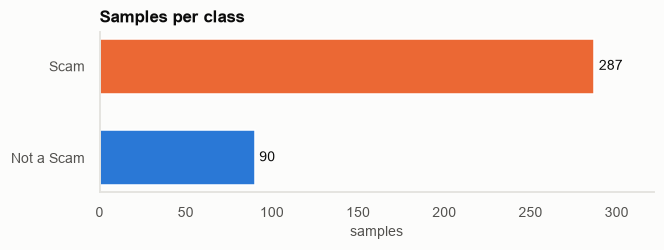

,dialogue,scam_class,scam_type
0,ผู้โทร: สวัสดีครับ ผมสารวัตรชยพัฒน์ กองปราบปราม ติดต่อคุณสมชายใช่ไหมครับ ผู้รับ: ผมครับ มีอะไรครับ ผู้โทร: มีหมายจับคุณนะครับ จากข้อหาเกี่ยวข้องกับการฟอกเงิน เราจับคนมาหนึ่งคนแล้วเขาอ้างชื่อคุณ ผู...,Scam,Police Impersonation
1,ผู้โทร: สวัสดีค่ะ พี่แอนเองค่ะ โทรมาจากไปรษณีย์ไทย มีพัสดุจากต่างประเทศส่งถึงคุณมานี ผู้รับ: อ๋อ มีพัสดุเหรอคะ แต่ฉันไม่ได้สั่งของนะ ผู้โทร: เป็นของมีค่าถูกส่งมาจากออสเตรเลีย แต่ติดที่ศุลกากร ต้อง...,Scam,Delivery Service Impersonation
2,"ผู้โทร: สวัสดีครับ ผมโทรมาจากธนาคารกสิกรไทย แผนกบัตรเครดิต ตอนนี้บัตรของคุณมีการใช้จ่ายที่นิวยอร์ก 50,000 บาท สงสัยว่ามีการโจรกรรม ผู้รับ: อะไรนะครับ! ผมไม่ได้ไปนิวยอร์กนะ ระงับเลยครับ ผู้โทร: ผมจ...",Scam,Bank OTP Phishing


In [119]:
if EXCEL_SOURCE is not None and EXCEL_SOURCE.exists():
    converted = convert_excel(EXCEL_SOURCE, DATA_FILE)
    print(
        f"{EXCEL_SOURCE.name} -> {DATA_FILE.name}:",
        "converted" if converted else "already up to date",
    )

raw = load_raw(DATA_FILE)
raw = raw.dropna(subset=["dialogue", "scam_class"]).reset_index(drop=True)
raw["dialogue"] = raw["dialogue"].astype(str)
raw["scam_class"] = raw["scam_class"].astype(str).str.strip()
raw["scam_type"] = raw["scam_type"].fillna("").astype(str).str.strip()

unknown_classes = sorted(set(raw["scam_class"].str.lower()) - set(SCAM_CLASS_VALUES))
if unknown_classes:
    raise ValueError(f"scam_class values not in SCAM_CLASS_VALUES: {unknown_classes}")

unparsed = raw["dialogue"].map(parse_dialogue).map(len) < 2
print(f"dialogues that do not split into 2 or more turns: {unparsed.sum()} of {len(raw)}")
if unparsed.mean() > MAX_UNPARSED_SHARE:
    raise ValueError(
        "Most dialogues do not match ROLE_TAGS, so the format has changed. "
        "Edit ROLE_TAGS or parse_dialogue in the input format cell. First dialogue:\n"
        + raw["dialogue"].iat[0][:300]
    )

print(raw.shape)
class_counts = raw["scam_class"].value_counts()

fig, ax = plt.subplots(figsize=(6.5, 1.9))
ax.barh(
    class_counts.index,
    class_counts.to_numpy(),
    height=0.6,
    color=[CLASS_COLORS.get(c, NEUTRAL) for c in class_counts.index],
)
label_bars(ax)
ax.invert_yaxis()
ax.set(title="Samples per class", xlabel="samples", xlim=(0, class_counts.max() * 1.12))
plt.show()

raw.head(3)

## Step 2. Exploratory data analysis (EDA): data leakage

Data leakage means the input holds a clue to the label that will not exist at inference time.
A classifier uses any such shortcut. This cell counts three of them.

- Hang-up notes such as `[วางสาย]` and `[ตัดสาย]`. In the demo file only scam samples have them.
- Narration inside a caller turn, such as `ผู้โทรส่งแบบฟอร์มปลอมให้กรอกเลขบัตรและบัญชี`. It describes
  the scam in the third person. A real caller never says it, and some of these lines contain
  the English label name.
- Mixed layout: some samples put each turn on a new line, the rest are one line.

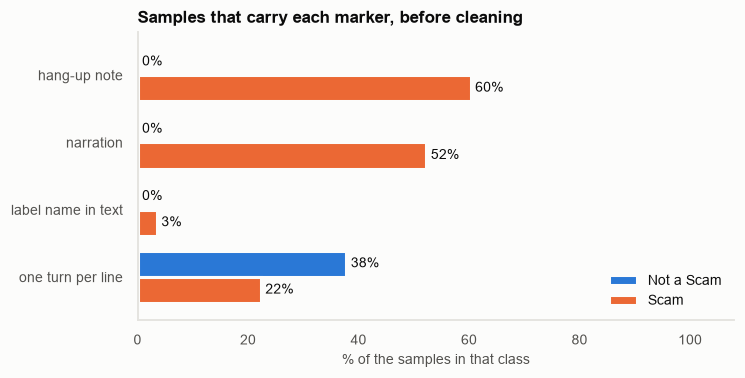

scam_class,Not a Scam,Scam
hang-up note,0,173
narration,0,150
label name in text,0,10
one turn per line,34,64


In [120]:
def has_narration(dialogue: str) -> bool:
    return any(
        role == "caller" and NARRATION.search(" ".join(text.split()))
        for role, text in parse_dialogue(dialogue)
    )


checks = pd.DataFrame(
    {
        "hang-up note": raw["dialogue"].str.contains(BRACKET_NOTE),
        "narration": raw["dialogue"].map(has_narration),
        "label name in text": raw["dialogue"].str.contains(LABEL_NAMES),
        "one turn per line": raw["dialogue"].str.contains("\n"),
    }
)
by_class = checks.groupby(raw["scam_class"])
share = (by_class.mean() * 100).T

ax = share.plot.barh(
    figsize=(7, 3.4), width=0.78, edgecolor=SURFACE, linewidth=2,
    color=[CLASS_COLORS.get(c, NEUTRAL) for c in share.columns],
)  # fmt: skip
label_bars(ax, "{:.0f}%")
ax.invert_yaxis()
ax.set(
    title="Samples that carry each marker, before cleaning",
    xlabel="% of the samples in that class",
    xlim=(0, 108),
)
ax.legend(title=None, loc="lower right")
plt.show()

by_class.sum().T.style.background_gradient(cmap=BLUES, axis=None)

## Step 3. Data cleaning and text preprocessing

For each sample:

1. Split the dialogue into turns at the `ผู้โทร:` and `ผู้รับ:` tags.
2. Remove bracket notes, stage notes such as `(เสียงร้องไห้)`, and caller narration.
3. Normalize the text with `pythainlp.util.normalize`: it removes zero-width characters and
   repeated or misplaced vowels and tone marks, which look the same on screen but are
   different strings to a model. Then keep one space between words.
4. Drop turns that are now empty and join consecutive turns from the same speaker.
5. Rewrite the dialogue as `A: ...` / `B: ...`, one turn per line.

The last step matches what the classifier sees in the app. `CallState._render` in
`tts_voice_agent/memory.py` builds the text as `"{speaker}: {text}"` joined by newlines, and
the diarizer names speakers A, B in the order they first speak. The Thai role tags would
never appear at run time, so the model should not train on them.

In [121]:
# The web system calls this same function, so training and serving see the same text.
from nlp_core.text import normalize_text


def clean_turns(dialogue: str) -> list[tuple[str, str]]:
    """Return [(role, text), ...] with notes and narration removed."""
    turns: list[tuple[str, str]] = []
    for role, text in parse_dialogue(dialogue):
        text = BRACKET_NOTE.sub(" ", text)
        text = STAGE_NOTE.sub(" ", text)
        text = normalize_text(text)
        if role == "caller":
            text = normalize_text(NARRATION.sub(" ", text))
        if not text:
            continue
        if turns and turns[-1][0] == role:
            turns[-1] = (role, f"{turns[-1][1]} {text}")
        else:
            turns.append((role, text))
    return turns


def speaker_turns(turns: list[tuple[str, str]]) -> list[dict]:
    """Name speakers A, B by who speaks first, like the diarizer does."""
    letters: dict[str, str] = {}
    out = []
    for role, text in turns:
        if role not in letters:
            letters[role] = "AB"[len(letters)]
        out.append(
            {"speaker": letters[role], "role": role, "start": None, "end": None, "text": text}
        )
    return out


def render(turns: list[dict]) -> str:
    return "\n".join(f"{t['speaker']}: {t['text']}" for t in turns)


df = raw.copy()
df["speaker_turns"] = df["dialogue"].map(clean_turns).map(speaker_turns)
df["text"] = df["speaker_turns"].map(render)

marked = checks.index[checks["narration"] & checks["hang-up note"]]
example = marked[0] if len(marked) else raw.index[0]
print("BEFORE\n" + raw.loc[example, "dialogue"])
print("\nAFTER\n" + df.loc[example, "text"])

BEFORE
ผู้โทร: ขอเวลาสักครู่ครับ เรื่องหุ้นบริษัทก่อนเข้าตลาด ของคุณกำลังมีปัญหา ถ้าปล่อยไว้จะกระทบสิทธิ์ ผู้โทรเสนอเงินปันผลก้อนใหญ่จากหุ้นที่ไม่มีเอกสารยืนยัน ผู้รับ: ฟังดูแปลก ๆ นะคะ ฉันไม่ได้ดำเนินการอะไรไว้ ผู้โทร: ผมช่วยจัดการให้ได้ แต่ต้องบอกเลขบัตรและรหัสที่ส่งเข้าโทรศัพท์ก่อน ห้ามวางสายเพราะรายการจะค้าง ผู้รับ: ผมจะไม่กดลิงก์และไม่บอกรหัสใด ๆ ขอไปตรวจสอบกับสำนักงานด้วยตัวเองครับ ผู้โทร: ถ้าไม่ทำตอนนี้จะมีปัญหาใหญ่! ผู้รับ: ฉันจะรับความเสี่ยงนั้นดีกว่าโอนเงินให้คนแปลกหน้า [วางสาย]

AFTER
A: ขอเวลาสักครู่ครับ เรื่องหุ้นบริษัทก่อนเข้าตลาด ของคุณกำลังมีปัญหา ถ้าปล่อยไว้จะกระทบสิทธิ์
B: ฟังดูแปลก ๆ นะคะ ฉันไม่ได้ดำเนินการอะไรไว้
A: ผมช่วยจัดการให้ได้ แต่ต้องบอกเลขบัตรและรหัสที่ส่งเข้าโทรศัพท์ก่อน ห้ามวางสายเพราะรายการจะค้าง
B: ผมจะไม่กดลิงก์และไม่บอกรหัสใด ๆ ขอไปตรวจสอบกับสำนักงานด้วยตัวเองครับ
A: ถ้าไม่ทำตอนนี้จะมีปัญหาใหญ่!
B: ฉันจะรับความเสี่ยงนั้นดีกว่าโอนเงินให้คนแปลกหน้า


Check that the cleaning worked. A sample that fails a check is dropped and printed, so one
odd dialogue in a new version of the spreadsheet does not stop the notebook.

The last line counts `ผู้โทร` used as a normal word. A receiver can say it, so those samples
stay. Read them if the count jumps: it can also mean narration that the rule missed.

In [122]:
after = pd.DataFrame(
    {
        "bracket left": df["text"].str.contains(r"[\[\]]"),
        "role tag left": df["text"].str.contains(ROLE_TAG_LEFT),
        "label name left": df["text"].str.contains(LABEL_NAMES),
        "fewer than 2 turns": df["speaker_turns"].map(len) < 2,
    }
)
print(after.sum().to_string())

failed = after.any(axis=1)
if failed.any():
    print(f"\ndropped {failed.sum()} samples that failed a check:")
    print(df.loc[failed, "dialogue"].str.slice(0, 120).to_string())
df = df[~failed].reset_index(drop=True)
assert len(df), "no sample passed the cleaning checks"

print(f"\n{len(df)} samples left")
print(
    f"samples that still use the word {CALLER_TAG}:",
    int(df["text"].str.contains(CALLER_TAG, regex=False).sum()),
)

bracket left          0
role tag left         0
label name left       0
fewer than 2 turns    0

377 samples left
samples that still use the word ผู้โทร: 0


Length is one more thing that differs between the classes. The chart shows the number of
characters per dialogue after cleaning, and the table gives the median for each class.
Cleaning does not change this, so read the scores with it in mind.

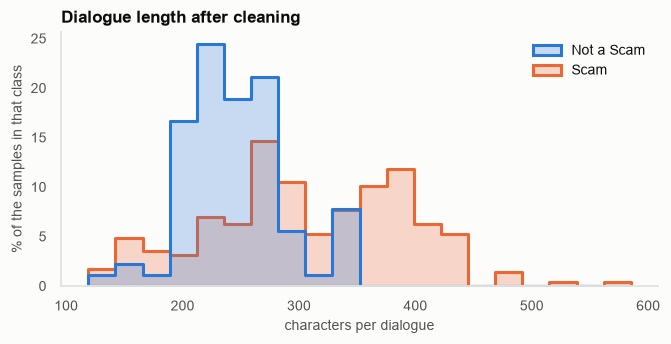

,median characters
scam_class,
Not a Scam,241.5
Scam,304.0


In [123]:
df["characters"] = df["text"].str.len()

fig, ax = plt.subplots(figsize=(7, 3))
sns.histplot(
    data=df, x="characters", hue="scam_class", hue_order=list(CLASS_COLORS), palette=CLASS_COLORS,
    bins=20, stat="percent", common_norm=False, element="step", alpha=0.25, linewidth=2, ax=ax,
)  # fmt: skip
ax.set(
    title="Dialogue length after cleaning",
    xlabel="characters per dialogue",
    ylabel="% of the samples in that class",
)
ax.get_legend().set_title(None)
plt.show()

df.groupby("scam_class")["characters"].median().rename("median characters").to_frame()

## Step 4. Label mapping (target variables)

The spec has a gate (`label_scam`) and 5 types (`label_type`). The spreadsheet has dozens of
type names. `TYPE_MAP` assigns each one to a spec type. `None` means "a scam, but none of the
5 types": the sample still trains the gate, and the type model skips it.

The mapping is a judgment call, so edit it if the team disagrees. A scam type name that is
not in the map is printed below and treated as `None`.

Exact duplicates are removed here, after the mapping. Two dialogues that differed only in a
hang-up note or a narration line are the same text after cleaning. If the copies agree on the
label, one is kept. If they disagree, the text does not decide the label, so every copy is
dropped and printed.


dropped 5 samples: same text, different labels
text
ATM Tax Refund Scam | Fake Delivery Phishing | Grant/Subsidy Scam
                                    Lost Item Scam | QR Code Scam
dropped 0 exact duplicates with the same label, 372 samples left


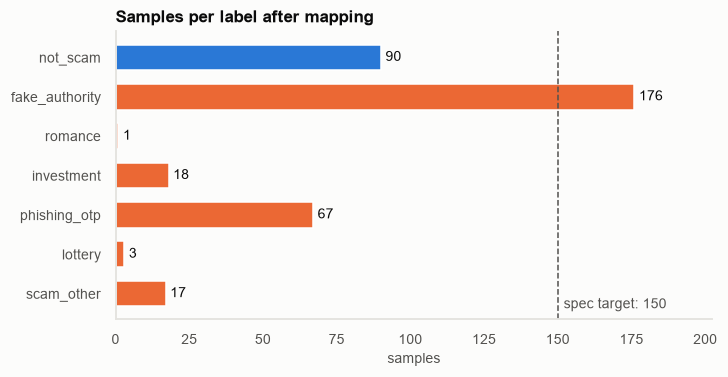

,samples,spec target,short by
stratum,,,
not_scam,90,150,60
fake_authority,176,150,0
romance,1,150,149
investment,18,150,132
phishing_otp,67,150,83
lottery,3,150,147
scam_other,17,0,0


In [124]:
TYPE_MAP: dict[str, str | None] = {
    # fake authority / call center: the caller claims to be an official or a company agent
    "Police Impersonation": "fake_authority",
    "Government Official Impersonation": "fake_authority",
    "Military Impersonation": "fake_authority",
    "Utility Impersonation": "fake_authority",
    "Bank Impersonation": "fake_authority",
    "Telecom Impersonation": "fake_authority",
    "Social Security Impersonation": "fake_authority",
    "Delivery Service Impersonation": "fake_authority",
    "Customs/Delivery Scam": "fake_authority",
    "Traffic Ticket Scam": "fake_authority",
    "Debt Collection Scam": "fake_authority",
    "Tax Deduction Scam": "fake_authority",
    "Tax Refund Scam": "fake_authority",
    "ATM Tax Refund Scam": "fake_authority",
    "Government Grant Scam": "fake_authority",
    "Government Compensation Scam": "fake_authority",
    "Grant/Subsidy Scam": "fake_authority",
    "Pension Scam": "fake_authority",
    "Student Loan Scam": "fake_authority",
    "Scholarship Scam": "fake_authority",
    "Insurance Claim Scam": "fake_authority",
    "Medical Insurance Scam": "fake_authority",
    # phishing / OTP: the goal is a code, a card number, a link, a QR scan or an app install
    "Bank OTP Phishing": "phishing_otp",
    "Fake Order Phishing": "phishing_otp",
    "Fake Delivery Phishing": "phishing_otp",
    "E-commerce Phishing": "phishing_otp",
    "Fake Flight Booking Scam": "phishing_otp",
    "Fake Hotel Booking Scam": "phishing_otp",
    "Tech Support Scam": "phishing_otp",
    "QR Code Scam": "phishing_otp",
    "Malware Download Scam": "phishing_otp",
    # investment
    "Investment Scam": "investment",
    "Dividend Scam": "investment",
    # lottery / prize
    "Lottery/Prize Scam": "lottery",
    "Prize/Lottery Scam": "lottery",
    # romance
    "Romance Scam": "romance",
    # scams outside the 5 spec types
    "Charity Scam": None,
    "Loan Approval Scam": None,
    "Overpayment Scam": None,
    "Family Emergency Scam": None,
    "Kidnapping/Family Emergency Scam": None,
    "Lost Item Scam": None,
}
assert set(filter(None, TYPE_MAP.values())) <= set(SCAM_TYPES)

df["label_scam"] = df["scam_class"].str.lower().map(SCAM_CLASS_VALUES).astype(bool)

unmapped = sorted(set(df.loc[df["label_scam"], "scam_type"]) - set(TYPE_MAP))
if unmapped:
    print("scam types missing from TYPE_MAP (treated as no type):", unmapped)

df["label_type"] = [
    TYPE_MAP.get(t) if is_scam else None
    for t, is_scam in zip(df["scam_type"], df["label_scam"], strict=True)
]
# The split is stratified on this column.
df["stratum"] = np.where(df["label_scam"], df["label_type"].fillna("scam_other"), "not_scam")

conflicting = df.groupby("text")["stratum"].transform("nunique") > 1
if conflicting.any():
    print(f"\ndropped {conflicting.sum()} samples: same text, different labels")
    print(
        df[conflicting]
        .groupby("text")["scam_type"]
        .agg(lambda s: " | ".join(sorted(set(s))))
        .to_string(index=False)
    )
before = len(df)
df = df[~conflicting].drop_duplicates(subset="text").reset_index(drop=True)
print(
    f"dropped {before - conflicting.sum() - len(df)} exact duplicates with the same label, {len(df)} samples left"
)

counts = df["stratum"].value_counts().rename("samples").to_frame()
counts["spec target"] = 150
counts.loc["scam_other", "spec target"] = 0
counts["short by"] = (counts["spec target"] - counts["samples"]).clip(lower=0)
counts = (
    counts.reindex(["not_scam", *SCAM_TYPES, "scam_other"])
    .fillna({"samples": 0, "spec target": 150, "short by": 150})
    .astype(int)
)

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh(
    counts.index, counts["samples"], height=0.65,
    color=[CLASS_COLORS["Not a Scam" if s == "not_scam" else "Scam"] for s in counts.index],
)  # fmt: skip
label_bars(ax)
ax.axvline(150, color=MUTED, linestyle="--", linewidth=1)
ax.text(152, len(counts) - 0.55, "spec target: 150", color=MUTED, fontsize=9, va="bottom")
ax.invert_yaxis()
ax.set(
    title="Samples per label after mapping",
    xlabel="samples",
    xlim=(0, max(counts["samples"].max(), 150) * 1.15),
)
plt.show()

counts.style.bar(subset=["short by"], color="#f5c2ad", vmin=0, vmax=150)

## Step 5. Near-duplicate detection

Many samples come from the same template with a few words changed. If one copy lands in train and
another in test, the test score measures memory of the template. This step puts samples that are
almost the same into one group, and step 6 keeps each group inside one split.

Similarity is the cosine between TF-IDF vectors of character n-grams. Samples are linked when
the similarity is at least `NEAR_DUPLICATE_SIMILARITY`, and a group is a set of linked samples.

The histogram shows, for each sample, how similar its closest other sample is. Samples to the right
of the dashed line have a near copy somewhere in the file.

372 samples in 204 groups
38 groups hold more than one sample (206 samples), largest has 26


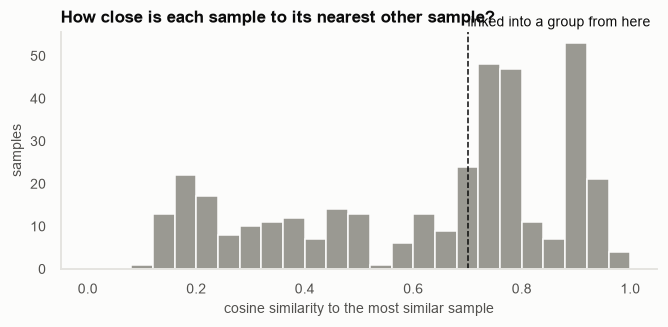


most similar pair (0.97):
A: ฮัลโหลครับ
B: ผมโทรจากฝ่ายบริการลูกค้า เรื่องขอจุดสังเกตบ้านที่คุณสอบถามไว้เมื่อวานครับ
A: อ๋อ ผมจำได้ ขอชื่อสาขากับเวลาที่ติดต่อไว้ด้วยครับ
B: ได้ครับ คุณสามารถโทรกลับเบอร์กลางที่หลังบัตรหรือเว็บไซต์ทางการเพื่อตรวจสอบได้
A: ขอบคุณครับ ผมจะตรวจสอบก่อนแล้วค่อยดำเนินการ ฉันจะจดวันเวลาไว้และตรวจสอบผ่านช่องทางทางการ หมายเลขรายการ 218 
---
A: ฮัลโหลครับ
B: ผมโทรจากฝ่ายบริการลูกค้า เรื่องขอจุดสังเกตบ้านที่คุณสอบถามไว้เมื่อวานครับ
A: อ๋อ ผมจำได้ ขอชื่อสาขากับเวลาที่ติดต่อไว้ด้วยครับ
B: ได้ครับ คุณสามารถโทรกลับเบอร์กลางที่หลังบัตรหรือเว็บไซต์ทางการเพื่อตรวจสอบได้
A: ขอบคุณครับ ผมจะตรวจสอบก่อนแล้วค่อยดำเนินการ ฉันจะจดวันเวลาไว้และตรวจสอบผ่านช่องทางทางการ หมายเลขรายการ 260


In [125]:
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.feature_extraction.text import TfidfVectorizer

body = df["text"].str.replace(r"(?m)^[AB]: ", "", regex=True)
vectors = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), sublinear_tf=True).fit_transform(
    body
)
similarity = (vectors @ vectors.T).toarray()
np.fill_diagonal(similarity, 0.0)

n_groups, df["group"] = connected_components(
    csr_matrix(similarity >= NEAR_DUPLICATE_SIMILARITY), directed=False
)
sizes = df["group"].value_counts()
print(f"{len(df)} samples in {n_groups} groups")
print(
    f"{(sizes > 1).sum()} groups hold more than one sample ({sizes[sizes > 1].sum()} samples), largest has {sizes.max()}"
)

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.hist(
    similarity.max(axis=1), bins=25, range=(0, 1), color=NEUTRAL, edgecolor=SURFACE, linewidth=1
)
ax.axvline(NEAR_DUPLICATE_SIMILARITY, color=INK, linestyle="--", linewidth=1)
ax.text(
    NEAR_DUPLICATE_SIMILARITY,
    1.01,
    "linked into a group from here",
    transform=ax.get_xaxis_transform(),
    color=INK,
    fontsize=9,
    va="bottom",
)
ax.set(
    title="How close is each sample to its nearest other sample?",
    xlabel="cosine similarity to the most similar sample",
    ylabel="samples",
)
plt.show()

a, b = np.unravel_index(similarity.argmax(), similarity.shape)
print(f"\nmost similar pair ({similarity[a, b]:.2f}):")
print(df.loc[a, "text"], "\n---\n" + df.loc[b, "text"])

## Step 6. Train / validation / test split (70 / 15 / 15)

The spec asks for a fixed split with seed 42, stratified by `label_type`. This version also
keeps every near-duplicate group in one split.

Groups are shuffled with the seed and handled largest first. Each group goes to the split
that is furthest below its target sample count for that group's label.

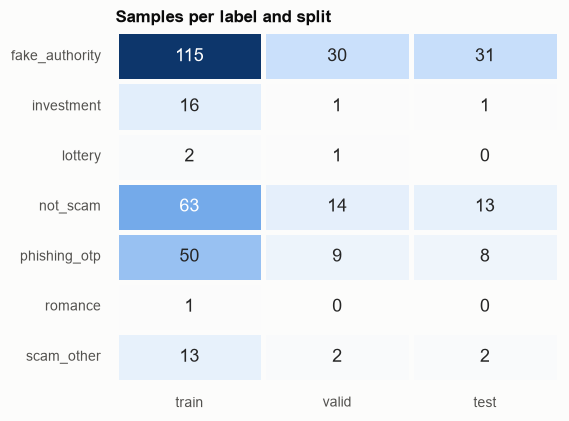

split,train,valid,test
stratum,,,
fake_authority,115,30,31
investment,16,1,1
lottery,2,1,0
not_scam,63,14,13
phishing_otp,50,9,8
romance,1,0,0
scam_other,13,2,2
total,260,57,55


In [126]:
def group_stratified_split(frame: pd.DataFrame, ratios: dict[str, float], seed: int) -> pd.Series:
    groups = (
        frame.groupby("group")
        .agg(stratum=("stratum", lambda s: s.mode().iat[0]), n=("stratum", "size"))
        .sample(frac=1.0, random_state=seed)
        .sort_values("n", ascending=False, kind="stable")
    )
    totals = groups.groupby("stratum")["n"].sum()
    filled: dict[str, Counter] = defaultdict(Counter)
    assigned: dict[int, str] = {}
    for g in groups.itertuples():
        gaps = {
            name: ratio * totals[g.stratum] - filled[g.stratum][name]
            for name, ratio in ratios.items()
        }
        split = max(gaps, key=gaps.get)
        assigned[g.Index] = split
        filled[g.stratum][split] += g.n
    return frame["group"].map(assigned)


df["split"] = group_stratified_split(df, SPLIT_RATIOS, SEED)
assert df.groupby("group")["split"].nunique().max() == 1, "a group was cut across splits"

table = pd.crosstab(df["stratum"], df["split"]).reindex(columns=list(SPLIT_RATIOS), fill_value=0)

fig, ax = plt.subplots(figsize=(5.2, 0.42 * len(table) + 1.2))
table_heatmap(table, ax, "d")
ax.set(title="Samples per label and split", xlabel="", ylabel="")
plt.show()

table.loc["total"] = table.sum()
table

## Step 7. Export the processed dataset

One sample per row, with the fields of the record schema in `docs/spec.html` as columns.
A csv cell cannot hold a list, so `speaker_turns` and `entities` are written as JSON text
and parsed again when part B reads the file. Fields this dataset cannot fill
(`audio_path`, `entities`, `reference_summary`, `scam_start_turn`) are empty. `raw_type` keeps
the original spreadsheet type so the mapping can be changed later without the raw file.
`group` is the near-duplicate group from step 5. Cross-validation in step 12 needs it to keep
near copies in the same fold. Both are extra columns, not part of the spec schema.

Every record passes a schema check before the files are written.

In [127]:
RECORD_KEYS = (
    "id", "channel", "text", "audio_path", "speaker_turns", "label_scam", "label_type",
    "entities", "reference_summary", "scam_start_turn", "source", "raw_type", "group",
)  # fmt: skip


def to_record(sample) -> dict:
    return {
        "id": f"call_{sample.Index + 1:05d}",
        "channel": "call",
        "text": sample.text,
        "audio_path": None,
        "speaker_turns": sample.speaker_turns,
        "label_scam": bool(sample.label_scam),
        "label_type": sample.label_type,
        "entities": [],
        "reference_summary": None,
        "scam_start_turn": None,
        "source": "synthetic",
        "raw_type": sample.scam_type,
        "group": int(sample.group),
    }


def check_record(rec: dict) -> None:
    assert tuple(rec) == RECORD_KEYS, f"{rec.get('id')}: wrong keys"
    assert rec["channel"] in ("call", "message")
    assert rec["text"].strip(), f"{rec['id']}: empty text"
    assert isinstance(rec["label_scam"], bool)
    assert rec["label_type"] is None or rec["label_type"] in SCAM_TYPES, (
        f"{rec['id']}: bad label_type"
    )
    assert rec["label_scam"] or rec["label_type"] is None, f"{rec['id']}: type on a normal call"
    assert all(t["speaker"] and t["text"] for t in rec["speaker_turns"])


LIST_COLUMNS = ("speaker_turns", "entities")  # stored as JSON text inside the csv


def write_records(path: Path, records: list[dict]) -> None:
    frame = pd.DataFrame(records, columns=list(RECORD_KEYS))
    for col in LIST_COLUMNS:
        frame[col] = frame[col].map(lambda value: json.dumps(value, ensure_ascii=False))
    frame.to_csv(path, index=False, encoding=CSV_ENCODING)


split_files = {name: PROCESSED / f"{name}.csv" for name in SPLIT_RATIOS}

if REBUILD_SPLIT or not all(p.exists() for p in split_files.values()):
    df["label_type"] = df["label_type"].astype(object).where(df["label_type"].notna(), None)
    records = {name: [] for name in SPLIT_RATIOS}
    for sample in df.itertuples():
        rec = to_record(sample)
        check_record(rec)
        records[sample.split].append(rec)
    PROCESSED.mkdir(parents=True, exist_ok=True)
    write_records(PROCESSED / "dataset.csv", [r for name in SPLIT_RATIOS for r in records[name]])
    for name, path in split_files.items():
        write_records(path, records[name])
        print(f"wrote {len(records[name]):4d} records to {path.relative_to(ROOT)}")
else:
    print("kept the split on disk (REBUILD_SPLIT is False)")

wrote  260 records to data\processed\train.csv
wrote   57 records to data\processed\valid.csv
wrote   55 records to data\processed\test.csv


# Part B. Modeling and evaluation

From here on the notebook reads only `data/processed/{train,valid,test}.csv`.

- Gate labels: `not_scam`, `scam`. Trained on every sample.
- Type labels: the spec types that have at least `MIN_TYPE_SAMPLES` samples in total and at
  least `MIN_TYPE_EVAL_SAMPLES` in valid and in test. Trained on scam samples with one of those
  types. The other types are listed as not enough data and are not scored.
- `outside` holds the scam samples the type model never trains on: scams with no spec type
  and scams of a type without enough data. Step 13 uses them to check what the type model
  answers for a scam it does not know.

In [128]:
def read_records(path: Path) -> pd.DataFrame:
    frame = pd.read_csv(path, encoding=CSV_ENCODING)
    for col in LIST_COLUMNS:
        frame[col] = frame[col].map(json.loads)
    # An empty csv cell is read as NaN. Turn it back into None.
    return frame.astype(object).where(frame.notna(), None).astype({"label_scam": bool})


data = {name: read_records(PROCESSED / f"{name}.csv") for name in SPLIT_RATIOS}

GATE_LABELS = ["not_scam", "scam"]
for frame in data.values():
    frame["gate"] = frame["label_scam"].astype(int)

type_counts = (
    pd.DataFrame({name: frame["label_type"].value_counts() for name, frame in data.items()})
    .reindex(SCAM_TYPES)
    .fillna(0)
    .astype(int)
)
type_counts["total"] = type_counts.sum(axis=1)

enough = (
    (type_counts["total"] >= MIN_TYPE_SAMPLES)
    & (type_counts["train"] > 0)
    & (type_counts[["valid", "test"]] >= MIN_TYPE_EVAL_SAMPLES).all(axis=1)
)
TYPE_LABELS = [t for t in SCAM_TYPES if enough[t]]
NOT_ENOUGH_DATA = [t for t in SCAM_TYPES if not enough[t]]
TRAIN_TYPE_MODEL = len(TYPE_LABELS) >= 2

typed = {name: frame[frame["label_type"].isin(TYPE_LABELS)].copy() for name, frame in data.items()}
for frame in typed.values():
    frame["type"] = frame["label_type"].map(TYPE_LABELS.index)

# The type model sees none of these in training, whatever split they are in.
outside = pd.concat(
    [
        frame[frame["label_scam"] & ~frame["label_type"].isin(TYPE_LABELS)]
        for frame in data.values()
    ],
    ignore_index=True,
)
TYPE_MIN_CONFIDENCE = 0.50  # below this the type model's answer is dropped (steps 13 and 14)

print("type model trains on:", TYPE_LABELS)
print("not enough data:     ", NOT_ENOUGH_DATA)
print("scam samples outside the trained types:", len(outside))
type_counts.style.background_gradient(cmap=BLUES, axis=None)

type model trains on: ['fake_authority', 'phishing_otp']
not enough data:      ['romance', 'investment', 'lottery']
scam samples outside the trained types: 39


,train,valid,test,total
label_type,,,,
fake_authority,115,30,31,176
romance,1,0,0,1
investment,16,1,1,18
phishing_otp,50,9,8,67
lottery,2,1,0,3


## Step 8. Baseline model: TF-IDF features + logistic regression

A baseline is a simple model that the fine-tuned model has to beat. Its features are TF-IDF
weights. Thai has no spaces between words, so the text is first cut into words with
PyThaiNLP (`newmm`, a dictionary-based tokenizer), then counts words and word pairs.
`class_weight="balanced"` stops it from always answering with the biggest class.

`score` is the one scoring function in this notebook. Every model goes through it with the
test set, so the numbers are comparable. It also prints a 95% bootstrap interval for
macro-F1: the range the score would fall in if the test set were drawn again. A wide
interval means the test set is too small to trust the number. It draws two tables: the confusion matrix on the
left (true label down the side, predicted label across the top) and precision, recall and
F1 for each class on the right.

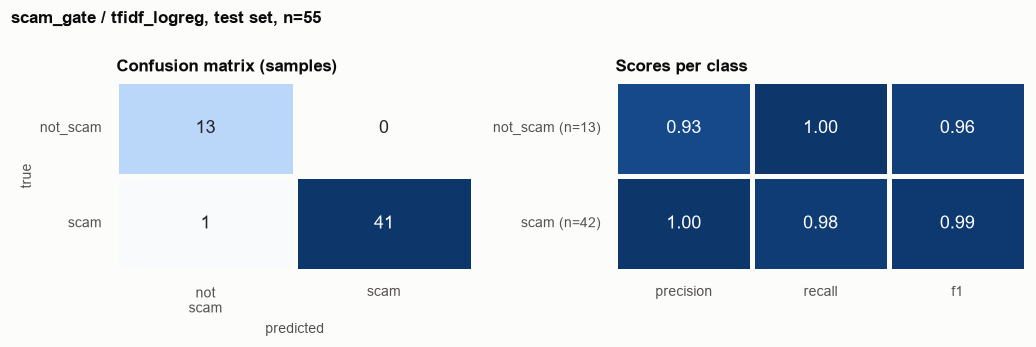

scam_gate / tfidf_logreg: macro  P=0.964  R=0.988  F1=0.975  (95% interval for F1: 0.91 to 1.00)


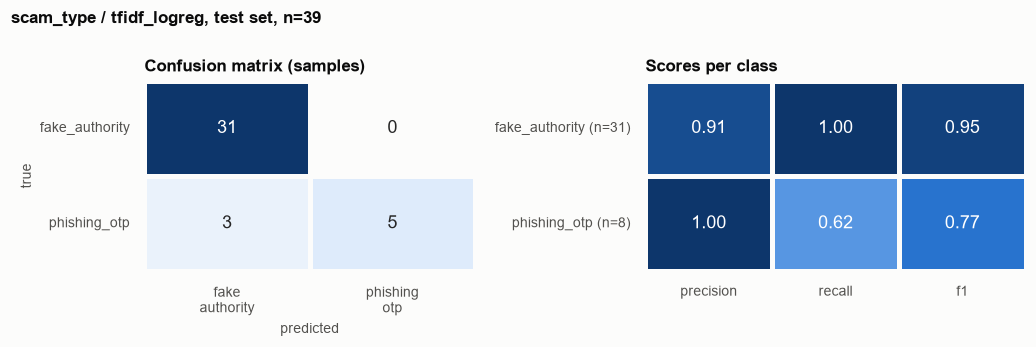

scam_type / tfidf_logreg: macro  P=0.956  R=0.812  F1=0.862  (95% interval for F1: 0.64 to 1.00)


In [129]:
from pythainlp.tokenize import word_tokenize
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
)
from sklearn.pipeline import make_pipeline

results: list[dict] = []
N_BOOTSTRAP = 2000  # resamples of the test set for the confidence interval


def score(task: str, model: str, y_true, y_pred, label_names: list[str]) -> None:
    """Draw the confusion matrix and per-class P/R/F1, print the macro scores, keep the numbers."""
    ids = list(range(len(label_names)))
    p, r, f1, support = precision_recall_fscore_support(y_true, y_pred, labels=ids, zero_division=0)
    per_class = pd.DataFrame(
        {"precision": p, "recall": r, "f1": f1, "support": support}, index=label_names
    )
    macro = per_class[["precision", "recall", "f1"]].mean()
    # Bootstrap: draw the test set again with replacement many times and score each draw.
    # The middle 95% of those scores is the interval.
    truth, guess = np.asarray(y_true), np.asarray(y_pred)
    draws = np.random.default_rng(SEED).integers(0, len(truth), size=(N_BOOTSTRAP, len(truth)))
    resampled = [
        f1_score(truth[i], guess[i], labels=ids, average="macro", zero_division=0) for i in draws
    ]
    ci_low, ci_high = np.percentile(resampled, [2.5, 97.5])
    matrix = pd.DataFrame(
        confusion_matrix(y_true, y_pred, labels=ids),
        index=[f"true {n}" for n in label_names],
        columns=[f"pred {n}" for n in label_names],
    )
    fig, (left, right) = plt.subplots(
        1, 2, figsize=(9.5, 0.5 * len(label_names) + 2.2), width_ratios=[1, 1.15]
    )
    wrapped = [name.replace("_", "\n") for name in label_names]
    table_heatmap(matrix.set_axis(label_names, axis=0).set_axis(wrapped, axis=1), left, "d")
    left.set(title="Confusion matrix (samples)", xlabel="predicted", ylabel="true")
    shown = per_class[["precision", "recall", "f1"]].set_axis(
        [f"{name} (n={n})" for name, n in zip(label_names, support, strict=True)]
    )
    table_heatmap(shown, right, ".2f", vmin=0, vmax=1)
    right.set_title("Scores per class")
    fig.suptitle(
        f"{task} / {model}, test set, n={len(y_true)}",
        x=0.01,
        ha="left",
        fontsize=11,
        fontweight="bold",
    )
    fig.tight_layout()
    plt.show()
    print(
        f"{task} / {model}: macro  P={macro['precision']:.3f}  R={macro['recall']:.3f}  F1={macro['f1']:.3f}"
        f"  (95% interval for F1: {ci_low:.2f} to {ci_high:.2f})"
    )
    results.append(
        {
            "task": task,
            "model": model,
            "precision": round(float(macro["precision"]), 4),
            "recall": round(float(macro["recall"]), 4),
            "f1": round(float(macro["f1"]), 4),
            "f1_ci_low": round(float(ci_low), 4),
            "f1_ci_high": round(float(ci_high), 4),
            "accuracy": round(float(accuracy_score(y_true, y_pred)), 4),
            "n_test": int(len(y_true)),
            "per_class": per_class.round(4).to_dict(orient="index"),
        }
    )


def thai_words(text: str) -> list[str]:
    return word_tokenize(text, engine="newmm", keep_whitespace=False)


def make_baseline():
    return make_pipeline(
        TfidfVectorizer(
            tokenizer=thai_words,
            token_pattern=None,
            lowercase=False,
            ngram_range=(1, 2),
            sublinear_tf=True,
            min_df=2,
        ),
        LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED),
    )


gate_baseline = make_baseline().fit(data["train"]["text"], data["train"]["gate"])
score(
    "scam_gate",
    "tfidf_logreg",
    data["test"]["gate"],
    gate_baseline.predict(data["test"]["text"]),
    GATE_LABELS,
)

if TRAIN_TYPE_MODEL:
    type_baseline = make_baseline().fit(typed["train"]["text"], typed["train"]["type"])
    score(
        "scam_type",
        "tfidf_logreg",
        typed["test"]["type"],
        type_baseline.predict(typed["test"]["text"]),
        TYPE_LABELS,
    )

### Which speaker does the gate rely on?

The same baseline is trained three times: on the full dialogue, on the caller's turns only,
and on the receiver's turns only. It is scored on valid, so the test set stays untouched.

A scam call is defined by what the caller does. If the receiver's turns alone score as high
as the full dialogue, the gate can be solved from how the receiver reacts, and in this
dataset the receiver of a scam call almost always refuses. A model trained on that will be
weaker on calls where the victim goes along.

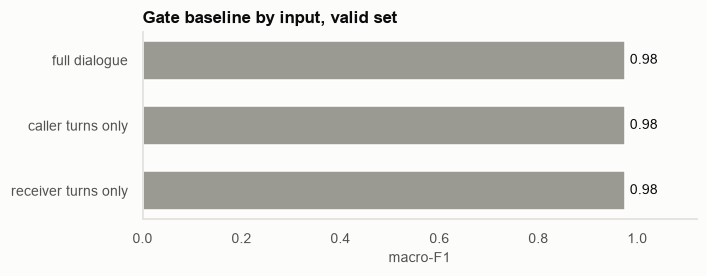

,valid macro-F1
full dialogue,0.976
caller turns only,0.976
receiver turns only,0.976


In [130]:
def turns_of(frame: pd.DataFrame, role: str) -> pd.Series:
    return frame["speaker_turns"].map(
        lambda turns: " ".join(t["text"] for t in turns if t["role"] == role)
    )


gate_inputs = {
    "full dialogue": lambda frame: frame["text"],
    "caller turns only": lambda frame: turns_of(frame, "caller"),
    "receiver turns only": lambda frame: turns_of(frame, "receiver"),
}
speaker_f1 = {}
for name, pick in gate_inputs.items():
    model = make_baseline().fit(pick(data["train"]), data["train"]["gate"])
    speaker_f1[name] = f1_score(
        data["valid"]["gate"], model.predict(pick(data["valid"])), average="macro"
    )
speaker_f1 = pd.Series(speaker_f1, name="valid macro-F1")

fig, ax = plt.subplots(figsize=(6.5, 2.2))
ax.barh(speaker_f1.index, speaker_f1.to_numpy(), height=0.6, color=NEUTRAL)
label_bars(ax, "{:.2f}")
ax.invert_yaxis()
ax.set(title="Gate baseline by input, valid set", xlabel="macro-F1", xlim=(0, 1.12))
plt.show()

speaker_f1.round(3).to_frame()

## Step 9. Tokenization

Two things to settle before training:

- Spaces. WangchanBERTa tokenizers need every space written as `<_>`. PhayaThaiBERT extends
  that vocabulary, so the cell checks whether `<_>` is a token and applies the rule only if it
  is. Newlines between turns become spaces first.
- Length. The token counts below show whether `MAX_LENGTH` cuts any dialogue.

device: NVIDIA GeForce RTX 5070 Ti
space token in use: True
tokens per dialogue: {'count': 372, 'mean': 93, 'std': 22, 'min': 45, '25%': 77, '50%': 92, '75%': 110, 'max': 185}
dialogues longer than 256 tokens: 0


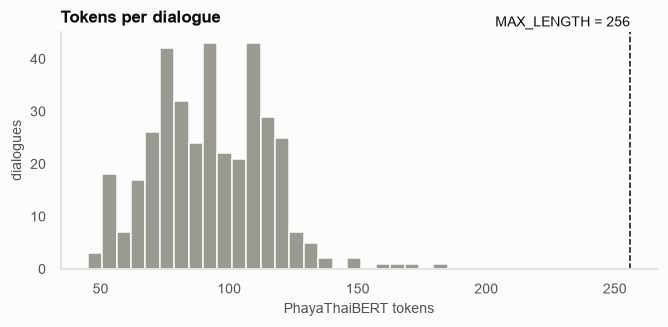

['▁', 'A', ':', '<_>', '▁อ้าว', '<_>', '▁คุณ', 'สม', 'ปอง', 'เอง', 'เหรอครับ', '<_>', '▁ยินดีด้วย', 'นะครับ', '<_>', '▁ท่าน', 'ได้', 'ร']


In [131]:
import torch
from transformers import AutoTokenizer

MODEL_ID = "clicknext/phayathaibert"
MAX_LENGTH = 256

torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(
    "device:", torch.cuda.get_device_name(0) if device == "cuda" else "cpu (training will be slow)"
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
SPACE_TOKEN = "<_>"
USE_SPACE_TOKEN = SPACE_TOKEN in tokenizer.get_vocab()


def to_model_text(text: str) -> str:
    text = " ".join(text.split())
    return text.replace(" ", SPACE_TOKEN) if USE_SPACE_TOKEN else text


lengths = pd.concat(data.values())["text"].map(
    lambda t: len(tokenizer(to_model_text(t))["input_ids"])
)
print("space token in use:", USE_SPACE_TOKEN)
print("tokens per dialogue:", lengths.describe().round(0).astype(int).to_dict())
print(f"dialogues longer than {MAX_LENGTH} tokens: {(lengths > MAX_LENGTH).sum()}")

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.hist(lengths, bins=25, color=NEUTRAL, edgecolor=SURFACE, linewidth=1)
ax.axvline(MAX_LENGTH, color=INK, linestyle="--", linewidth=1)
ax.text(
    MAX_LENGTH,
    1.01,
    f"MAX_LENGTH = {MAX_LENGTH}",
    transform=ax.get_xaxis_transform(),
    color=INK,
    fontsize=9,
    va="bottom",
    ha="right",
)
ax.set(title="Tokens per dialogue", xlabel="PhayaThaiBERT tokens", ylabel="dialogues")
plt.show()

sample = to_model_text(data["train"]["text"].iat[0])[:60]
print(tokenizer.tokenize(sample))

## Step 10. Model training: fine-tune the gate classifier

`fine_tune` is shared by the gate and the type model.

- The loss function is cross-entropy with class weights, so the minority class counts as much
  as the majority class.
- After each epoch the model is scored on valid. The epoch with the best valid macro-F1 is kept.
  The two charts after training show loss and valid macro-F1 for each epoch. Train loss that
  keeps falling while valid loss rises means the model is overfitting.
- The test set is not touched here.

The classifier head is new and starts from random weights. Only the encoder below it comes from
the pretrained PhayaThaiBERT checkpoint. Training is what fits the head to the task.

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 973.49it/s] 


Epoch,Training Loss,Validation Loss,Macro F1,Accuracy
1,0.473328,0.269637,0.975734,0.982456
2,0.068405,0.425262,0.950175,0.964912
3,0.061681,0.305207,0.975734,0.982456
4,0.031546,0.366878,0.950175,0.964912
5,0.065430,0.374321,0.950175,0.964912
6,0.027832,0.328539,0.975734,0.982456


Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.17s/it]


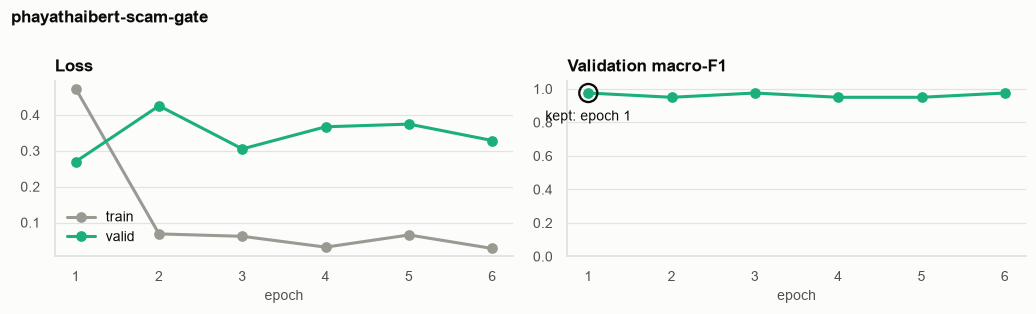

best valid macro-F1: 0.976


In [132]:
from torch.utils.data import Dataset
from transformers import (
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    PrinterCallback,
    Trainer,
    TrainingArguments,
)
from transformers import logging as hf_logging

# Hyperparameters
LEARNING_RATE = 3e-5
BATCH_SIZE = 16


class TextDataset(Dataset):
    def __init__(self, texts, labels):
        self.encodings = tokenizer(
            [to_model_text(t) for t in texts], truncation=True, max_length=MAX_LENGTH
        )
        self.labels = [int(y) for y in labels]

    def __len__(self) -> int:
        return len(self.labels)

    def __getitem__(self, i: int) -> dict:
        item = {key: values[i] for key, values in self.encodings.items()}
        item["labels"] = self.labels[i]
        return item


class WeightedTrainer(Trainer):
    def __init__(self, *args, class_weights: torch.Tensor, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits.float()
        loss = torch.nn.functional.cross_entropy(
            logits, labels, weight=self.class_weights.to(logits.device)
        )
        return (loss, outputs) if return_outputs else loss


def valid_metrics(eval_pred) -> dict:
    y_pred = eval_pred.predictions.argmax(axis=-1)
    _, _, f1, _ = precision_recall_fscore_support(
        eval_pred.label_ids, y_pred, average="macro", zero_division=0
    )
    return {"macro_f1": f1, "accuracy": accuracy_score(eval_pred.label_ids, y_pred)}


def plot_history(trainer: Trainer, name: str) -> None:
    """Loss per epoch on the left, valid macro-F1 per epoch on the right."""
    log = pd.DataFrame(trainer.state.log_history)
    train = log.dropna(subset=["loss"]).set_index("epoch") if "loss" in log else pd.DataFrame()
    valid = log.dropna(subset=["eval_macro_f1"]).set_index("epoch")
    valid_color = MODEL_COLORS["phayathaibert"]

    fig, (left, right) = plt.subplots(1, 2, figsize=(9.5, 2.9))
    if len(train):
        left.plot(train.index, train["loss"], color=NEUTRAL, linewidth=2, marker="o", label="train")
    left.plot(
        valid.index, valid["eval_loss"], color=valid_color, linewidth=2, marker="o", label="valid"
    )
    left.set(title="Loss", xlabel="epoch")
    left.legend()

    best = valid["eval_macro_f1"].idxmax()
    right.plot(valid.index, valid["eval_macro_f1"], color=valid_color, linewidth=2, marker="o")
    right.scatter(
        [best],
        [valid.loc[best, "eval_macro_f1"]],
        s=140,
        facecolors="none",
        edgecolors=INK,
        linewidths=1.5,
        zorder=3,
    )
    right.annotate(
        f"kept: epoch {best:.0f}", (best, valid.loc[best, "eval_macro_f1"]),
        xytext=(0, -18), textcoords="offset points", ha="center", fontsize=9,
    )  # fmt: skip
    right.set(title="Validation macro-F1", xlabel="epoch", ylim=(0, 1.05))
    for ax in (left, right):
        ax.set_xticks(valid.index)
        ax.grid(axis="y", color=GRID, linewidth=0.8)
    fig.suptitle(name, x=0.01, ha="left", fontsize=11, fontweight="bold")
    fig.tight_layout()
    plt.show()


def fine_tune(
    name: str,
    train: pd.DataFrame,
    valid: pd.DataFrame,
    label_col: str,
    label_names: list[str],
    epochs: int,
    show: bool = True,
) -> Trainer:
    counts = np.bincount(train[label_col], minlength=len(label_names))
    class_weights = torch.tensor(
        len(train) / (len(label_names) * np.maximum(counts, 1)), dtype=torch.float
    )

    # The pretrained checkpoint has a masked-language-model head (lm_head) and no classifier
    # head. transformers reports the first as unexpected and the second as newly initialized.
    # Both are what fine-tuning expects, so the report is hidden for this one call.
    verbosity = hf_logging.get_verbosity()
    hf_logging.set_verbosity_error()
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_ID,
        num_labels=len(label_names),
        id2label=dict(enumerate(label_names)),
        label2id={n: i for i, n in enumerate(label_names)},
    )
    hf_logging.set_verbosity(verbosity)
    total_steps = math.ceil(len(train) / BATCH_SIZE) * epochs
    args = TrainingArguments(
        output_dir=str(CHECKPOINTS / name),
        num_train_epochs=epochs,
        learning_rate=LEARNING_RATE,
        per_device_train_batch_size=BATCH_SIZE,
        per_device_eval_batch_size=32,
        warmup_steps=int(0.1 * total_steps),
        weight_decay=0.01,
        eval_strategy="epoch",
        save_strategy="epoch",
        logging_strategy="epoch",
        save_total_limit=1,
        load_best_model_at_end=True,
        metric_for_best_model="macro_f1",
        greater_is_better=True,
        fp16=device == "cuda",
        report_to="none",
        disable_tqdm=not show,
        seed=SEED,
    )
    trainer = WeightedTrainer(
        model=model,
        args=args,
        train_dataset=TextDataset(train["text"], train[label_col]),
        eval_dataset=TextDataset(valid["text"], valid[label_col]),
        data_collator=DataCollatorWithPadding(tokenizer),
        compute_metrics=valid_metrics,
        class_weights=class_weights,
    )
    if not show:
        # Cross-validation trains many models; keep their per-epoch logs out of the output.
        trainer.remove_callback(PrinterCallback)
    trainer.train()
    if show:
        plot_history(trainer, name)
        print(f"best valid macro-F1: {trainer.state.best_metric:.3f}")
    return trainer


def predict_ids(trainer: Trainer, frame: pd.DataFrame, label_col: str) -> np.ndarray:
    return trainer.predict(TextDataset(frame["text"], frame[label_col])).predictions.argmax(axis=-1)


def top_probability(trainer: Trainer, frame: pd.DataFrame) -> np.ndarray:
    """Highest class probability for each sample. The labels passed in are placeholders."""
    logits = trainer.predict(TextDataset(frame["text"], [0] * len(frame))).predictions
    return torch.tensor(logits).float().softmax(dim=-1).max(dim=-1).values.numpy()


def save(trainer: Trainer, name: str) -> Path:
    """Save the model, the tokenizer and the text preprocessing the model was trained with."""
    path = MODELS / name
    trainer.save_model(str(path))
    tokenizer.save_pretrained(str(path))
    preprocessing = {
        "input_format": "one turn per line, each line '<speaker letter>: <text>', speakers lettered A, B by first appearance",
        "normalize": "unicodedata NFC, then pythainlp.util.normalize, then collapse all whitespace to one space",
        "space_token": SPACE_TOKEN if USE_SPACE_TOKEN else None,
        "max_length": MAX_LENGTH,
    }
    (path / "preprocessing.json").write_text(
        json.dumps(preprocessing, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    # The best model is saved, so the training checkpoints (several GB) can go.
    shutil.rmtree(CHECKPOINTS / name, ignore_errors=True)
    return path


gate_trainer = fine_tune(
    "phayathaibert-scam-gate", data["train"], data["valid"], "gate", GATE_LABELS, epochs=6
)

In [133]:
gate_test_pred = predict_ids(gate_trainer, data["test"], "gate")
GATE_DIR = save(gate_trainer, "phayathaibert-scam-gate")

# Free the GPU before the next model.
del gate_trainer
torch.cuda.empty_cache()

Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.35s/it]


## Step 11. Model training: fine-tune the type classifier

Same function, trained only on scam samples whose type has enough data. It runs more epochs
because it sees fewer samples.

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 861.98it/s]


Epoch,Training Loss,Validation Loss,Macro F1,Accuracy
1,0.712185,0.657276,0.434783,0.769231
2,0.680533,0.570194,0.584615,0.769231
3,0.529872,0.409705,0.811958,0.871795
4,0.293559,0.275556,0.865517,0.897436
5,0.110997,0.274601,0.819444,0.846154
6,0.062949,0.285501,0.927778,0.948718
7,0.017848,0.292674,0.865517,0.897436
8,0.008045,0.325456,0.895629,0.923077
9,0.004358,0.345337,0.895629,0.923077
10,0.003648,0.349156,0.895629,0.923077


Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.17s/it]


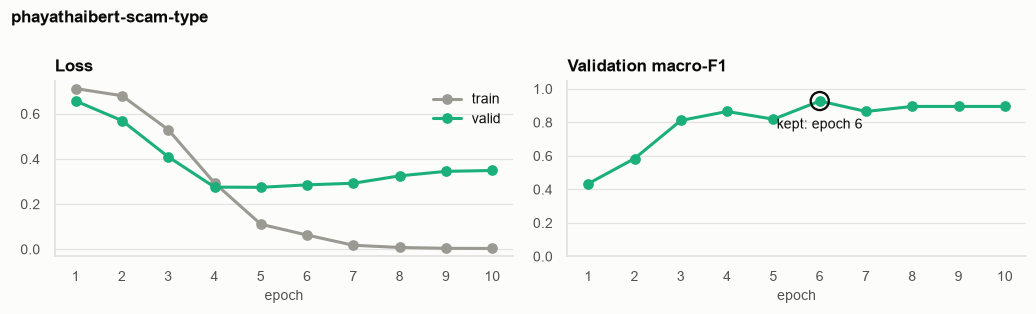

best valid macro-F1: 0.928


Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.35s/it]


In [134]:
if TRAIN_TYPE_MODEL:
    type_trainer = fine_tune(
        "phayathaibert-scam-type", typed["train"], typed["valid"], "type", TYPE_LABELS, epochs=10
    )
    type_test_pred = predict_ids(type_trainer, typed["test"], "type")
    outside_confidence = top_probability(type_trainer, outside) if len(outside) else np.array([])
    TYPE_DIR = save(type_trainer, "phayathaibert-scam-type")
    del type_trainer
    torch.cuda.empty_cache()
else:
    TYPE_DIR = None
    print("fewer than 2 scam types have enough samples, so there is no type model yet")

## Step 12. Cross-validation

One train / valid / test split gives one score, and with a few dozen test samples that score
moves a lot with which samples happen to land in test. K-fold cross-validation repeats the
experiment: the train and valid samples are pooled and cut into `N_FOLDS` folds, and each
fold takes one turn as the held-out part. Every pooled sample is scored once by a model
that never saw it, so the estimate rests on several times more samples than the test set.

- The test set stays out of the pool. Step 13 still uses it once.
- Folds are stratified by label and grouped by near-duplicate group, like the split in step 6.
- The baseline trains on the other folds. PhayaThaiBERT also needs a validation set to pick
  its best epoch, so it trains on all but two folds and uses the next fold for that. The
  held-out fold is used only for scoring.

Read the chart like this: each dot is one fold, the bar is the mean. If the dots of the two
models overlap, the folds do not show that one model is better.

With `RUN_BERT_CV = True` this step trains `N_FOLDS` models per task, about `N_FOLDS` times
the training time of steps 10 and 11. Set it to `False` to cross-validate the baseline only.

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 838.10it/s]


Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.18s/it]


Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.16s/it]


Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.20s/it]


Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.40s/it]


Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.29s/it]


... (90 outputs left out)

Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.17s/it]


Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.16s/it]


Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.19s/it]


scam_type: fold 5 of 5 done


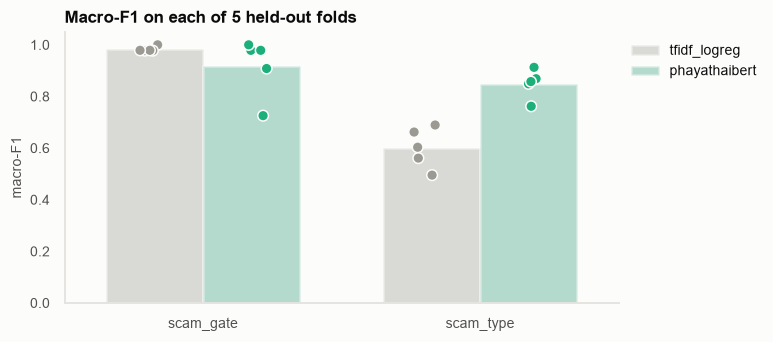

,task,model,mean,std,min,max
0,scam_gate,phayathaibert,0.918,0.113,0.726,1.000
1,scam_gate,tfidf_logreg,0.983,0.010,0.978,1.000
2,scam_type,phayathaibert,0.850,0.055,0.762,0.913
3,scam_type,tfidf_logreg,0.602,0.078,0.495,0.689


In [135]:
from sklearn.model_selection import StratifiedGroupKFold

N_FOLDS = 5
RUN_BERT_CV = True


def cross_validate(
    task: str, frame: pd.DataFrame, label_col: str, label_names: list[str], epochs: int
) -> pd.DataFrame:
    """Macro-F1 of each model on each held-out fold."""
    frame = frame.reset_index(drop=True)
    splitter = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
    folds = [held_out for _, held_out in splitter.split(frame, frame[label_col], frame["group"])]
    ids = list(range(len(label_names)))
    rows = []
    for k, score_idx in enumerate(folds):
        fit_idx = np.setdiff1d(frame.index, score_idx)
        y_true = frame.loc[score_idx, label_col]
        baseline = make_baseline().fit(frame.loc[fit_idx, "text"], frame.loc[fit_idx, label_col])
        predictions = {"tfidf_logreg": baseline.predict(frame.loc[score_idx, "text"])}
        if RUN_BERT_CV:
            select_idx = folds[(k + 1) % N_FOLDS]
            train_idx = np.setdiff1d(fit_idx, select_idx)
            name = f"cv-{task}-fold{k + 1}"
            trainer = fine_tune(
                name,
                frame.loc[train_idx],
                frame.loc[select_idx],
                label_col,
                label_names,
                epochs,
                show=False,
            )
            predictions["phayathaibert"] = predict_ids(trainer, frame.loc[score_idx], label_col)
            del trainer
            torch.cuda.empty_cache()
            shutil.rmtree(CHECKPOINTS / name, ignore_errors=True)
        for model, y_pred in predictions.items():
            f1 = f1_score(y_true, y_pred, labels=ids, average="macro", zero_division=0)
            rows.append(
                {
                    "task": task,
                    "model": model,
                    "fold": k + 1,
                    "samples": len(score_idx),
                    "macro_f1": f1,
                }
            )
        print(f"{task}: fold {k + 1} of {N_FOLDS} done")
    return pd.DataFrame(rows)


cv_parts = [
    cross_validate(
        "scam_gate", pd.concat([data["train"], data["valid"]]), "gate", GATE_LABELS, epochs=6
    )
]
if TRAIN_TYPE_MODEL:
    cv_parts.append(
        cross_validate(
            "scam_type", pd.concat([typed["train"], typed["valid"]]), "type", TYPE_LABELS, epochs=10
        )
    )
cv_scores = pd.concat(cv_parts, ignore_index=True)

cv_models = [m for m in MODEL_COLORS if m in set(cv_scores["model"])]
fig, ax = plt.subplots(figsize=(6.5, 3.2))
sns.barplot(
    data=cv_scores, x="task", y="macro_f1", hue="model", hue_order=cv_models, palette=MODEL_COLORS,
    errorbar=None, alpha=0.35, width=0.7, edgecolor=SURFACE, linewidth=2, ax=ax,
)  # fmt: skip
sns.stripplot(
    data=cv_scores, x="task", y="macro_f1", hue="model", hue_order=cv_models, palette=MODEL_COLORS,
    dodge=True, jitter=0.08, size=7, edgecolor=SURFACE, linewidth=1, legend=False, ax=ax,
)  # fmt: skip
ax.set(
    title=f"Macro-F1 on each of {N_FOLDS} held-out folds",
    xlabel="",
    ylabel="macro-F1",
    ylim=(0, 1.05),
)
ax.legend(title=None, loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.show()

cv_summary = (
    cv_scores.groupby(["task", "model"])["macro_f1"]
    .agg(["mean", "std", "min", "max"])
    .round(3)
    .reset_index()
)
cv_summary.style.format(precision=3).bar(subset=["mean"], vmin=0, vmax=1, color="#b7d3f6")

## Step 13. Model evaluation on the test set

Both PhayaThaiBERT models are scored on the test set with the same `score` function as the
baseline. This is the score the spec asks for. Compare it with the cross-validation mean
from step 12: if the two are far apart, the test set is the less reliable one, because it
is smaller. The type score uses test samples that are scams of a trained type, so it measures the
type model alone and not the gate's mistakes.

The type model has no "other" answer. The histogram shows how sure it is on the `outside`
samples, scams of a type it never trained on. Every sample to the right of the dashed line
would get a type from `predict`, and that type is wrong by definition. If most of them are on
the right, raise `TYPE_MIN_CONFIDENCE` or collect data for the missing types.

The bar chart and the summary table hold the macro averages. Per-class numbers are in the
tables above them and in `models/scam_classifier_metrics.json`.

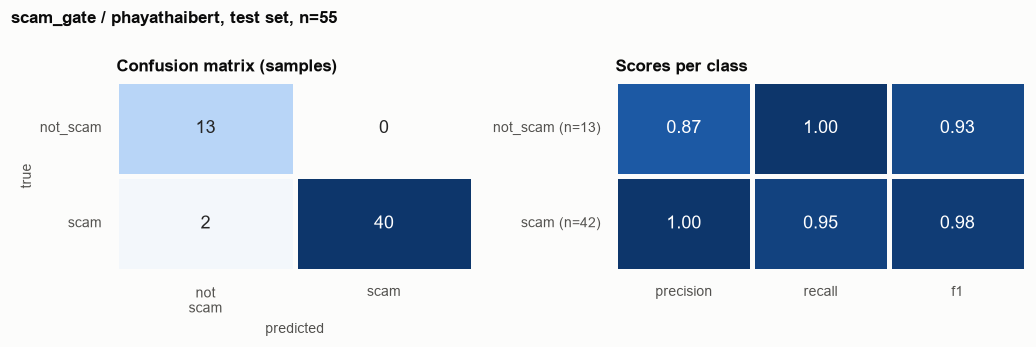

scam_gate / phayathaibert: macro  P=0.933  R=0.976  F1=0.952  (95% interval for F1: 0.87 to 1.00)


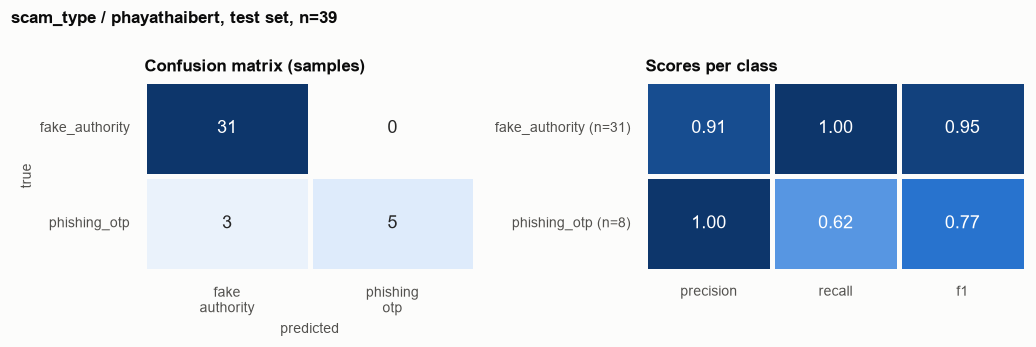

scam_type / phayathaibert: macro  P=0.956  R=0.812  F1=0.862  (95% interval for F1: 0.68 to 1.00)


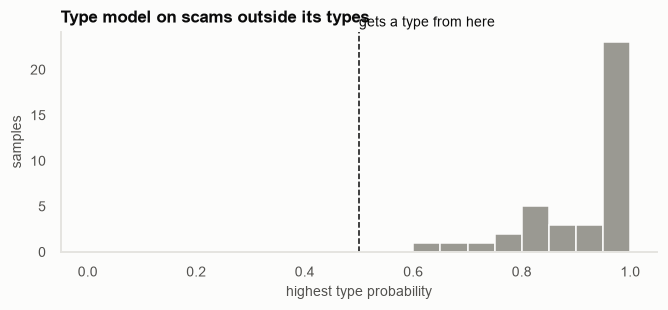

39 of 39 scam samples outside the trained types would get a type
not scored, not enough data: ['romance', 'investment', 'lottery']


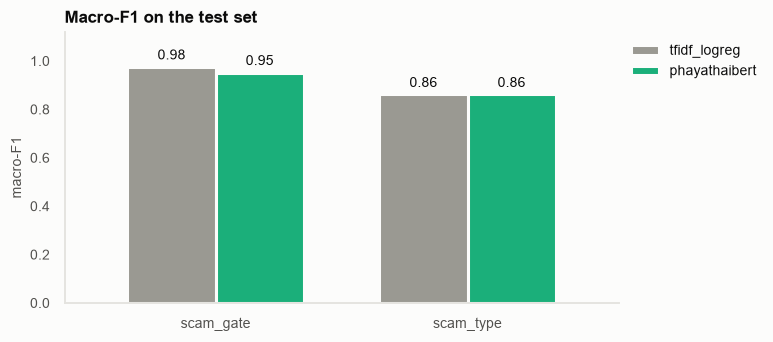

,task,model,precision,recall,f1,f1_ci_low,f1_ci_high,accuracy,n_test
0,scam_gate,phayathaibert,0.933,0.976,0.952,0.869,1.000,0.964,55
1,scam_gate,tfidf_logreg,0.964,0.988,0.976,0.912,1.000,0.982,55
2,scam_type,phayathaibert,0.956,0.812,0.862,0.677,1.000,0.923,39
3,scam_type,tfidf_logreg,0.956,0.812,0.862,0.639,1.000,0.923,39


In [136]:
score("scam_gate", "phayathaibert", data["test"]["gate"], gate_test_pred, GATE_LABELS)
if TRAIN_TYPE_MODEL:
    score("scam_type", "phayathaibert", typed["test"]["type"], type_test_pred, TYPE_LABELS)

# Scam samples outside the trained types: how many would still get a type?
outside_typed = None
if TRAIN_TYPE_MODEL and len(outside):
    outside_typed = int((outside_confidence >= TYPE_MIN_CONFIDENCE).sum())
    fig, ax = plt.subplots(figsize=(7, 2.6))
    ax.hist(
        outside_confidence, bins=20, range=(0, 1), color=NEUTRAL, edgecolor=SURFACE, linewidth=1
    )
    ax.axvline(TYPE_MIN_CONFIDENCE, color=INK, linestyle="--", linewidth=1)
    ax.text(
        TYPE_MIN_CONFIDENCE,
        1.01,
        "gets a type from here",
        transform=ax.get_xaxis_transform(),
        color=INK,
        fontsize=9,
        va="bottom",
    )
    ax.set(
        title="Type model on scams outside its types",
        xlabel="highest type probability",
        ylabel="samples",
    )
    plt.show()
    print(
        f"{outside_typed} of {len(outside)} scam samples outside the trained types would get a type"
    )

metrics = {
    "model_id": MODEL_ID,
    "seed": SEED,
    "samples": {name: int(len(frame)) for name, frame in data.items()},
    "type_labels": TYPE_LABELS,
    "not_enough_data": NOT_ENOUGH_DATA,
    "cross_validation": {
        "folds": N_FOLDS,
        "pool": "train + valid",
        "macro_f1": cv_summary.to_dict(orient="records"),
    },
    "type_min_confidence": TYPE_MIN_CONFIDENCE,
    "outside_types": {"samples": int(len(outside)), "given_a_type": outside_typed},
    "gate_baseline_valid_f1_by_input": speaker_f1.round(4).to_dict(),
    "results": results,
}
MODELS.mkdir(parents=True, exist_ok=True)
(MODELS / "scam_classifier_metrics.json").write_text(
    json.dumps(metrics, ensure_ascii=False, indent=2), encoding="utf-8"
)

summary = (
    pd.DataFrame(results)
    .drop(columns="per_class")
    .sort_values(["task", "model"])
    .reset_index(drop=True)
)
print("not scored, not enough data:", NOT_ENOUGH_DATA)

f1 = (
    summary.pivot(index="task", columns="model", values="f1")
    .reindex(columns=list(MODEL_COLORS))
    .dropna(axis=1, how="all")
)
ax = f1.plot.bar(
    figsize=(6.5, 3.2), width=0.7, rot=0, edgecolor=SURFACE, linewidth=2,
    color=[MODEL_COLORS[m] for m in f1.columns],
)  # fmt: skip
label_bars(ax, "{:.2f}")
ax.set(title="Macro-F1 on the test set", xlabel="", ylabel="macro-F1", ylim=(0, 1.12))
ax.legend(title=None, loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.show()

summary.style.format(precision=3).bar(
    subset=["precision", "recall", "f1", "accuracy"], vmin=0, vmax=1, color="#b7d3f6"
)

## Step 14. Inference

`ScamClassifier.predict` has the signature of the `ScamClassifier` protocol in
`nlp_core/interfaces.py`: it returns `(label_scam, label_type, confidence)`.

- If the gate's top probability is below `GATE_MIN_CONFIDENCE`, the answer is
  `(True, None, 0.0)`. An unsure answer is never treated as safe.
- `label_type` is filled only when the gate says scam and the type model is at least
  `TYPE_MIN_CONFIDENCE` sure.

Both thresholds are starting values. Tune them on valid before the model goes into the app.

In [137]:
GATE_MIN_CONFIDENCE = 0.60  # TYPE_MIN_CONFIDENCE is set at the start of part B


class ScamClassifier:
    def __init__(self, gate_dir: Path, type_dir: Path | None = None):
        self.tokenizer = AutoTokenizer.from_pretrained(gate_dir)
        self.gate = AutoModelForSequenceClassification.from_pretrained(gate_dir).to(device).eval()
        self.type = None
        if type_dir is not None:
            self.type = (
                AutoModelForSequenceClassification.from_pretrained(type_dir).to(device).eval()
            )

    @torch.no_grad()
    def _probabilities(self, model, text: str) -> torch.Tensor:
        text = to_model_text(normalize_text(text))
        inputs = self.tokenizer(
            text, truncation=True, max_length=MAX_LENGTH, return_tensors="pt"
        ).to(device)
        return model(**inputs).logits.float().softmax(dim=-1)[0].cpu()

    def predict(self, text: str) -> tuple[bool, str | None, float]:
        gate = self._probabilities(self.gate, text)
        confidence = float(gate.max())
        if confidence < GATE_MIN_CONFIDENCE:
            return True, None, 0.0
        is_scam = self.gate.config.id2label[int(gate.argmax())] == "scam"
        label_type = None
        if is_scam and self.type is not None:
            types = self._probabilities(self.type, text)
            if float(types.max()) >= TYPE_MIN_CONFIDENCE:
                label_type = self.type.config.id2label[int(types.argmax())]
        return is_scam, label_type, confidence


classifier = ScamClassifier(GATE_DIR, TYPE_DIR)

examples = [
    "A: สวัสดีครับ ผมร้อยตำรวจเอกจากกองปราบ บัญชีของคุณพัวพันคดีฟอกเงิน\nB: ผมไม่เคยทำอะไรแบบนั้นนะครับ\nA: ต้องโอนเงินมาให้ตรวจสอบภายในวันนี้ ห้ามวางสายและห้ามบอกใคร",
    "A: สวัสดีค่ะ โทรจากคลินิกทันตกรรมค่ะ ขอยืนยันนัดขูดหินปูนวันเสาร์สิบโมง\nB: ได้ค่ะ ไปตามนัดค่ะ\nA: ขอบคุณค่ะ แล้วพบกันวันเสาร์นะคะ",
]
for text in examples:
    print(classifier.predict(text), "<-", text.splitlines()[0])

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 938.62it/s]


(True, 'fake_authority', 0.9092806577682495) <- A: สวัสดีครับ ผมร้อยตำรวจเอกจากกองปราบ บัญชีของคุณพัวพันคดีฟอกเงิน
(False, None, 0.9405314922332764) <- A: สวัสดีค่ะ โทรจากคลินิกทันตกรรมค่ะ ขอยืนยันนัดขูดหินปูนวันเสาร์สิบโมง


## Limitations

- The data is generated and small. The test set has a few dozen samples, so one wrong answer
  moves a class score by several points. Use these as demo numbers.
- Cross-validation and the bootstrap interval show how much a score can move. They do not
  fix the data: every fold comes from the same templates, so all folds share the same
  shortcuts.
- If PhayaThaiBERT and the baseline score the same on a task, the fine-tuned model has not
  shown it is better. On a test set this small, a gap of two or three samples is not a result.
- A type is scored only if it has `MIN_TYPE_EVAL_SAMPLES` samples in valid and in test. The
  table at the start of part B lists the types that are left out, and step 4 shows how many
  samples each type is short of the spec target of 150.
- The type model cannot answer "none of these". Step 13 shows how many scams outside its
  types would still get a type.
- In almost every scam sample the receiver notices the scam and refuses. The chart after
  step 8 shows how far the receiver's turns alone get. Real victims often go along, so new
  scam data should include calls where the receiver complies, and new normal data should
  include receivers who are careful with a real caller.
- After the narration is removed, many scam samples share a template and differ only in the
  topic. The type label then depends on a few words, and some identical texts had different
  types in the spreadsheet (step 4 prints and drops them).
- Grouping stops at `NEAR_DUPLICATE_SIMILARITY`. Test samples can still share a looser
  template with train samples below that line, so the scores are higher than they would be
  on calls written from scratch.
- A few caller lines still use words a scammer would not say, such as `ปลอม`. They are left
  in because removing them by rule would damage normal sentences.
- The LLM classifier is not scored here. The spec's three-way comparison needs it run on the
  same `data/processed/test.csv`.

When the dataset grows, set `REBUILD_SPLIT = True` and rerun the notebook. New type names must be
added to `TYPE_MAP` in step 4. If the layout of the file changes, edit the input format cell
at the start of part A. The cleaning rules there (`BRACKET_NOTE`, `STAGE_NOTE`, `NARRATION`)
were written for this demo file, so run the step 2 check again on the new data and adjust them. Changing the split makes older scores incomparable, so
rerun every model after a rebuild.